# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model

This project uses the assignment's illustrative biological parameters: `r = 0.4` per week, `K = 10,000` tonnes and `N(0) = 4,000` tonnes. Export prices are an illustrative seeded random walk in UGX/kg, bounded to UGX 9,000–16,000. These model outputs are exploratory, not a catch quota or market forecast.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.fishery import (
    FishStock,
    PriceModel,
    RiskAssessor,
    value_at_risk,
    weekly_revenue_ugx,
)

## Fibonacci baseline (15 values)

The sequence is included only to demonstrate the previous baseline. Unbounded Fibonacci growth is biologically unrealistic because it has no carrying capacity, resource limitation or density dependence. It does not represent reproduction, recruitment or mortality rates. A stock model should instead be bounded by ecosystem productivity and include fishing removals. The discrete logistic model below is still simplified, but at least represents density-dependent growth.

In [2]:
fibonacci_stock = [1, 1]
for _ in range(13):
    fibonacci_stock.append(fibonacci_stock[-1] + fibonacci_stock[-2])
pd.DataFrame({"Step": np.arange(1, 16), "Fibonacci baseline (arbitrary units)": fibonacci_stock})

,Step,Fibonacci baseline (arbitrary units)
0,1,1
1,2,1
2,3,2
3,4,3
4,5,5
5,6,8
6,7,13
7,8,21
8,9,34
9,10,55


## Baseline logistic stock model

Each weekly catch is `h × N(t)` tonnes, taken from that week's stock, followed by density-dependent growth. Under the continuous logistic benchmark, the maximum sustainable yield is `rK/4 = 1,000 tonnes per week` for these parameters. This is a mathematical benchmark, not a recommended harvest quota; a discrete population model and uncertain real ecosystem may differ.

In [3]:
fish_stock = FishStock(initial_stock_tonnes=4_000, growth_rate=0.4, carrying_capacity_tonnes=10_000)
harvest_rates = (0.05, 0.10, 0.20, 0.30)
print(f"MSY benchmark: {fish_stock.maximum_sustainable_yield_tonnes_per_week:,.0f} tonnes/week")

MSY benchmark: 1,000 tonnes/week


## Seeded export-price paths and annual revenue risk

One thousand independent price paths are generated with a fixed seed. Weekly harvest is in tonnes, so the calculation converts to kilograms before multiplying by UGX/kg. The 5% VaR below is the fifth percentile of annual revenue: 5% of simulated years fall below that revenue level. This lower-tail revenue definition is made explicit because VaR conventions vary between loss and revenue reporting.

In [4]:
price_model = PriceModel(
    starting_price_ugx_per_kg=12_000,
    lower_bound_ugx_per_kg=9_000,
    upper_bound_ugx_per_kg=16_000,
    weekly_volatility_ugx_per_kg=350,
)
price_paths = price_model.simulate_paths(paths=1_000, weeks=52, seed=2026)
risk_assessor = RiskAssessor(low_cv_threshold=0.10, high_cv_threshold=0.20)
scenario_simulations = {}
scenario_annual_revenues = {}
scenario_rows = []

for harvest_rate in harvest_rates:
    simulation = fish_stock.simulate(harvest_rate, weeks=52)
    annual_revenues = weekly_revenue_ugx(simulation.harvest_tonnes, price_paths).sum(axis=1)
    revenue_stats = risk_assessor.revenue_statistics(annual_revenues)
    scenario_simulations[harvest_rate] = simulation
    scenario_annual_revenues[harvest_rate] = annual_revenues
    scenario_rows.append({
        "Harvest rate h": harvest_rate,
        "Final stock (tonnes)": simulation.final_stock_tonnes,
        "Annual catch (tonnes)": simulation.total_harvest_tonnes,
        "Mean annual revenue (UGX)": revenue_stats["mean_ugx"],
        "Revenue CV": revenue_stats["coefficient_of_variation"],
        "Risk class": risk_assessor.classify(revenue_stats["coefficient_of_variation"]),
        "5% revenue VaR (UGX)": value_at_risk(annual_revenues, confidence=0.95),
        "Mean weekly catch / MSY": simulation.total_harvest_tonnes / 52 / fish_stock.maximum_sustainable_yield_tonnes_per_week,
    })

scenario_table = pd.DataFrame(scenario_rows).set_index("Harvest rate h")
display(scenario_table.round(3))

,Final stock (tonnes),Annual catch (tonnes),Mean annual revenue (UGX),Revenue CV,Risk class,5% revenue VaR (UGX),Mean weekly catch / MSY
Harvest rate h,,,,,,,
0.05,8750.000,21714.612,2.616202e+11,0.109,Moderate,2.178701e+11,0.418
0.10,7500.000,37362.508,4.501399e+11,0.108,Moderate,3.751584e+11,0.719
0.20,4999.988,50871.711,6.128361e+11,0.106,Moderate,5.120703e+11,0.978
0.30,2503.717,42461.018,5.112944e+11,0.100,Low,4.323821e+11,0.817


## Revenue statistics and interpreting variance

These descriptive statistics use the `statistics` module over simulated annual revenues. Revenue variance has units of **UGX²**, not UGX, and depends on the scale of the revenue values. A fixed threshold such as 50,000 is therefore meaningless without a defined unit, scale, horizon and decision context. CV (standard deviation divided by mean) is dimensionless and more interpretable for relative variation, although its chosen classes below remain planning heuristics rather than universal safety standards.

In [5]:
reference_rate = 0.20
reference_revenue_stats = risk_assessor.revenue_statistics(scenario_annual_revenues[reference_rate])
display(pd.Series(reference_revenue_stats, name="h = 0.20").to_frame().round(3))
print("Risk boundaries used: Low CV < 10%; Moderate CV 10–20%; High CV ≥ 20%.")
print("These thresholds are analyst-selected screening categories, not sourced regulatory criteria.")

,h = 0.20
mean_ugx,6.128361e+11
median_ugx,6.107683e+11
variance_ugx_squared,4.242095e+21
standard_deviation_ugx,6.513137e+10
coefficient_of_variation,1.060000e-01


Risk boundaries used: Low CV < 10%; Moderate CV 10–20%; High CV ≥ 20%.
These thresholds are analyst-selected screening categories, not sourced regulatory criteria.


## Stock trajectories and annual revenue distribution

The first panel compares 52-week stock paths for all harvest rates. The second shows the Monte Carlo annual-revenue distribution for `h = 0.20`, with its lower 5% revenue quantile marked.

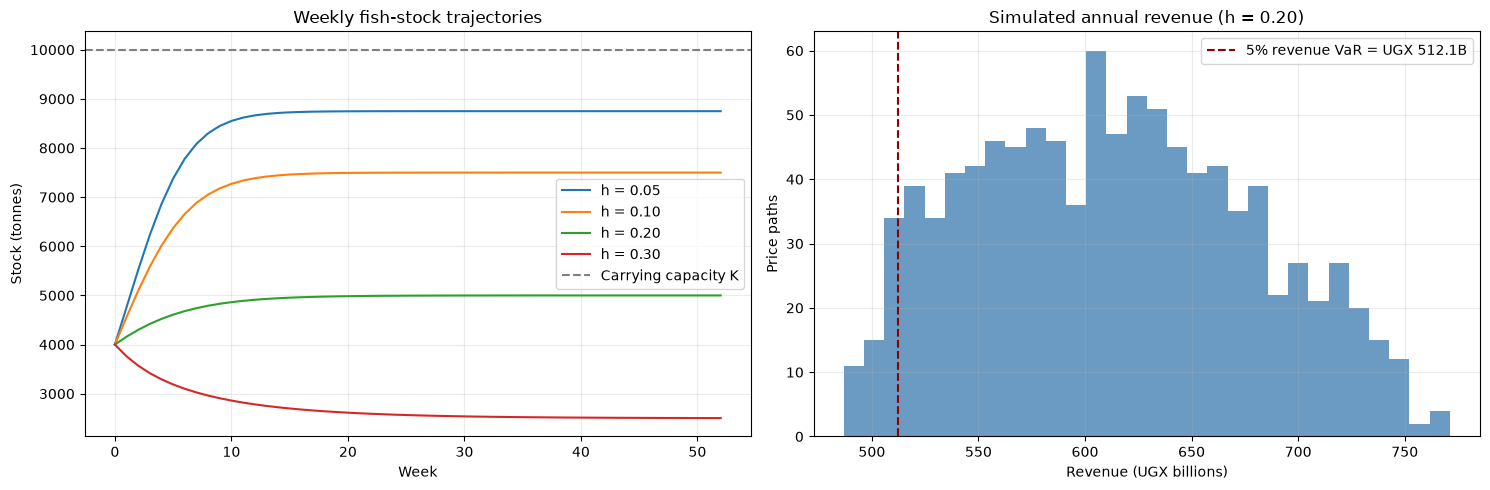

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for harvest_rate, simulation in scenario_simulations.items():
    axes[0].plot(np.arange(53), simulation.stock_tonnes, label=f"h = {harvest_rate:.2f}")
axes[0].axhline(fish_stock.carrying_capacity_tonnes, color="grey", linestyle="--", label="Carrying capacity K")
axes[0].set(title="Weekly fish-stock trajectories", xlabel="Week", ylabel="Stock (tonnes)")
axes[0].grid(alpha=0.25)
axes[0].legend()

reference_annual_revenue = scenario_annual_revenues[reference_rate]
revenue_var_5 = value_at_risk(reference_annual_revenue)
axes[1].hist(reference_annual_revenue / 1e9, bins=30, color="steelblue", alpha=0.8)
axes[1].axvline(revenue_var_5 / 1e9, color="darkred", linestyle="--", label=f"5% revenue VaR = UGX {revenue_var_5 / 1e9:.1f}B")
axes[1].set(title="Simulated annual revenue (h = 0.20)", xlabel="Revenue (UGX billions)", ylabel="Price paths")
axes[1].grid(alpha=0.25)
axes[1].legend()
fig.tight_layout()
plt.show()

## Extension: eight-week closed season over five years

For a like-for-like comparison, both five-year scenarios use the same 1,000 price paths. The closed period is the first eight weeks of each 52-week year, with no harvest during those weeks. Revenue is summed across the full 260-week horizon; the change is measured against continuous harvesting at `h = 0.20`.

In [7]:
five_year_prices = price_model.simulate_paths(paths=1_000, weeks=260, seed=2027)
continuous_five_year = fish_stock.simulate(0.20, weeks=260)
closed_five_year = fish_stock.simulate(0.20, weeks=260, closed_season_weeks=8)
continuous_revenue_paths = weekly_revenue_ugx(continuous_five_year.harvest_tonnes, five_year_prices).sum(axis=1)
closed_revenue_paths = weekly_revenue_ugx(closed_five_year.harvest_tonnes, five_year_prices).sum(axis=1)
mean_continuous_revenue = float(np.mean(continuous_revenue_paths))
mean_closed_revenue = float(np.mean(closed_revenue_paths))
revenue_change_percent = (mean_closed_revenue / mean_continuous_revenue - 1) * 100
closed_season_table = pd.DataFrame(
    [
        {"Scenario": "Continuous harvest", "Final stock (tonnes)": continuous_five_year.final_stock_tonnes, "Total catch (tonnes)": continuous_five_year.total_harvest_tonnes, "Mean five-year revenue (UGX)": mean_continuous_revenue},
        {"Scenario": "8-week closed season/year", "Final stock (tonnes)": closed_five_year.final_stock_tonnes, "Total catch (tonnes)": closed_five_year.total_harvest_tonnes, "Mean five-year revenue (UGX)": mean_closed_revenue},
    ]
).set_index("Scenario")
display(closed_season_table.round(2))
print(f"Closed-season mean revenue change vs continuous harvest: {revenue_change_percent:.2f}%")

,Final stock (tonnes),Total catch (tonnes),Mean five-year revenue (UGX)
Scenario,,,
Continuous harvest,5000.00,258871.70,3.179150e+12
8-week closed season/year,5000.11,235750.55,2.896351e+12


Closed-season mean revenue change vs continuous harvest: -8.90%


## Findings & Limitations

The logistic model approaches a harvest-dependent equilibrium rather than unbounded Fibonacci growth. Its theoretical continuous-model MSY is 1,000 tonnes per week at a stock of K/2; the simulated harvest paths show why high extraction can reduce the stock and eventually lower catch. For the stated parameters, the 0.20 rate is the benchmark rate associated with the logistic MSY, while a single 52-week run from 4,000 tonnes need not equal that equilibrium yield exactly. Simulated annual revenue increases with catch, but price uncertainty creates a spread in outcomes; the lower 5% quantile gives one transparent downside measure. Variance is expressed in UGX², so the old fixed threshold of 50,000 has no meaningful interpretation at these revenue magnitudes. CV-based labels are easier to compare but depend on explicitly chosen heuristic cutoffs.

The model assumes constant growth, carrying capacity and proportional harvest each week; it omits age structure, recruitment variability, species composition, illegal catch, environmental change, market demand and operating costs. The additive bounded random walk is illustrative and its volatility and bounds are not calibrated to observed fish prices. Monte Carlo VaR captures only this specified price-process uncertainty, not uncertainty in stock or harvest. The five-year closed-season comparison uses deterministic stock dynamics and shared simulated prices; it does not estimate compliance, displaced fishing effort, ecological recovery beyond the logistic equation or distributional impacts on fishers. None of the outputs should be treated as a management quota or revenue guarantee without validated biological and market data.

## References

- Course assignment prompt for the illustrative logistic-model parameters and project requirements.
- Schaefer, M. B. (1954). Some aspects of the dynamics of populations important to the management of the commercial marine fisheries. *Inter-American Tropical Tuna Commission Bulletin*, 1(2), 27–56. This classic surplus-production model motivates the logistic MSY benchmark; the notebook's discrete weekly simulation remains a simplifying adaptation.
- Food and Agriculture Organization of the United Nations (FAO), *Measuring capacity in fisheries* (Technical Paper 445): [capacity, related concepts and fisheries](https://www.fao.org/4/y5027e/y5027e04.htm).
- NumPy documentation: [`numpy.random.default_rng`](https://numpy.org/doc/stable/reference/random/generator.html) and [`numpy.quantile`](https://numpy.org/doc/stable/reference/generated/numpy.quantile.html).
- Python documentation: [`statistics`](https://docs.python.org/3/library/statistics.html).
- Price bounds, volatility and CV risk cutoffs are illustrative modeling assumptions, not externally calibrated estimates.